In [1]:
%pip install pytesseract


Note: you may need to restart the kernel to use updated packages.


In [2]:
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from IPython.display import display
from PIL import Image, ImageFile, ImageOps
import re 

ROOT = Path.cwd().parent
DATA = ROOT / "all_datasets"
RESULTS = ROOT / "results" / "lab06"
RESULTS.mkdir(parents=True, exist_ok=True)

ImageFile.LOAD_TRUNCATED_IMAGES = True
windows_default = Path(r"C:\Program Files\Tesseract-OCR\tesseract.exe")
tesseract = shutil.which("tesseract")
if tesseract is None and windows_default.is_file():
    tesseract = str(windows_default)

OCR_MODE = "live" if tesseract else "cached"
if OCR_MODE == "live":
    pytesseract.pytesseract.tesseract_cmd = tesseract
    print("OCR mode: live | Tesseract", pytesseract.get_tesseract_version(), "at", tesseract)
else:
    print("OCR mode: cached | install Tesseract and restart the kernel for a live rerun")

OCR mode: live | Tesseract 5.5.4 at /opt/homebrew/bin/tesseract


Labelled images: 89 | unique labels: 61


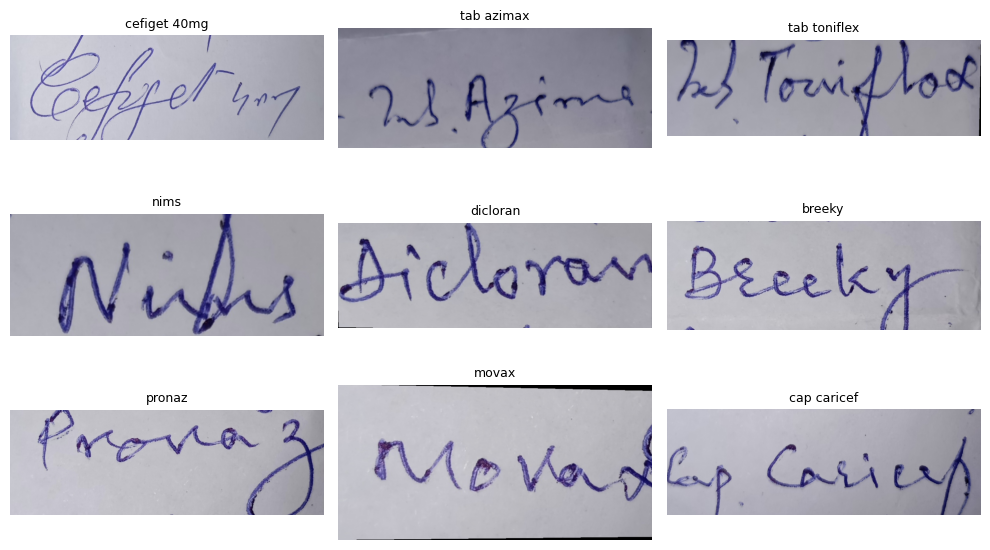

In [3]:
IMAGES = DATA / "lab06-ocr-handwritten-prescription"
if not IMAGES.exists():
    zipfile.ZipFile(DATA / "lab06-ocr-handwritten-prescription.zip").extractall(IMAGES)

labels = pd.read_csv(IMAGES / "doctor_handwriting_labels.csv")
labels["path"] = [IMAGES / "img" / "img" / name for name in labels.filename]
assert len(labels) == 89 and labels.filename.is_unique and all(p.exists() for p in labels.path)
print("Labelled images:", len(labels), "| unique labels:", labels.label.nunique())

def load_image(path):
    """Load the pixels now so the source file can close safely."""
    with Image.open(path) as image:
        return image.copy()

fig, axes = plt.subplots(3, 3, figsize=(10, 6))
for ax, row in zip(axes.flat, labels.head(9).itertuples()):
    ax.imshow(load_image(row.path))
    ax.set_title(row.label, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(RESULTS / "sample_grid.png", dpi=150)

In [4]:
OCR_CONFIG = "--oem 1 --psm 7"

def normalise(text):
    return re.sub(r"[^a-z0-9]", "", str(text).lower())

def run_ocr(paths, pipeline):
    """Return one auditable row per image, including engine status."""
    if OCR_MODE == "cached":
        cache_path = RESULTS / "predictions.csv"
        if not cache_path.is_file():
            raise RuntimeError("Tesseract is unavailable and predictions.csv is missing; install Tesseract and rerun.")
        cached = pd.read_csv(cache_path).fillna("")
        cached = cached[cached.pipeline == pipeline].copy()
        assert len(cached) == len(labels) and set(cached.filename) == set(labels.filename)
        cached["ocr_status"] = "cached"
        cached["ocr_detail"] = "validated prediction supplied with the course package"
        return cached

    rows = []
    for row, path in zip(labels.itertuples(), paths):
        try:
            prediction = pytesseract.image_to_string(load_image(path), config=OCR_CONFIG).strip()
            status, detail = "ok", ""
        except pytesseract.TesseractError as error:
            prediction = ""
            status, detail = "engine_error", error.message[:160]
        rows.append({"filename": row.filename, "pipeline": pipeline, "truth": row.label, "prediction": prediction, "truth_norm": normalise(row.label), "prediction_norm": normalise(prediction), "ocr_status": status, "ocr_detail": detail})
    return pd.DataFrame(rows)

baseline = run_ocr(labels.path, "baseline")
display(baseline[["truth", "prediction", "prediction_norm", "ocr_status"]].head(8))
print("OCR engine errors:", int((baseline.ocr_status == "engine_error").sum()))

,truth,prediction,prediction_norm,ocr_status
0,cefiget 40mg,,,ok
1,tab azimax,Ao,ao,ok
2,tab toniflex,p53 Towid host,p53towidhost,ok
3,nims,Nidu,nidu,ok
4,dicloran,diclerew,diclerew,ok
5,breeky,,,ok
6,pronaz,oan,oan,ok
7,movax,MA Vag,mavag,ok


OCR engine errors: 0


In [5]:
def levenshtein(a, b):
    """Minimum number of single-character edits that turn a into b."""
    previous = list(range(len(b) + 1))
    for i, char_a in enumerate(a, start=1):
        current = [i]
    for j, char_b in enumerate(b, start=1):
        current.append(min(current[j - 1] + 1, previous[j] + 1, previous[j - 1] + (char_a != char_b)))
    previous = current
    return previous[-1]

def add_distances(frame):
    frame = frame.copy()
    frame["exact"] = frame.truth_norm == frame.prediction_norm
    frame["edits"] = [levenshtein(t, p) for t, p in zip(frame.truth_norm, frame.prediction_norm)]
    longest = np.maximum(frame.truth_norm.str.len(), frame.prediction_norm.str.len()).clip(lower=1)
    frame["normalised_edit_distance"] = frame.edits / longest
    return frame

def summarise(frame):
    return {"pipeline": frame.pipeline.iat[0], "exact_match_accuracy": frame.exact.mean(),
            "mean_normalised_edit_distance": frame.normalised_edit_distance.mean(), "character_error_rate": frame.edits.sum() / frame.truth_norm.str.len().sum(), 
            "blank_predictions": int((frame.prediction_norm == "").sum())}

baseline = add_distances(baseline)
display(pd.DataFrame([summarise(baseline)]).round(4))

,pipeline,exact_match_accuracy,mean_normalised_edit_distance,character_error_rate,blank_predictions
0,baseline,0.0,0.8197,0.8169,43


In [6]:
def preprocess(path, output):
    image = ImageOps.exif_transpose(load_image(path)).convert("L")
    image = ImageOps.expand(image, border=20, fill=255)
    if image.width > 1200:
        image = image.resize((1200, round(image.height * 1200 / image.width)), Image.Resampling.LANCZOS)
        image = image.resize((round(image.width * 1.5), round(image.height * 1.5)), Image.Resampling.BICUBIC)
    image.save(output)
    return output

(RESULTS / "preprocessed").mkdir(exist_ok=True)
preprocessed_paths = [preprocess(path, RESULTS / "preprocessed" / f"{i:03d}.png") for i, path in enumerate(labels.path)]
example = Image.open(preprocessed_paths[0])
print("Prepared images:", len(preprocessed_paths), "| example size:", example.size, "mode:", example.mode)

Prepared images: 89 | example size: (1800, 638) mode: L


In [7]:
preprocessed = add_distances(run_ocr(preprocessed_paths, "grayscale_border_resize"))
pd.concat([baseline, preprocessed]).to_csv(RESULTS / "predictions.csv", index=False)

metrics = pd.DataFrame([summarise(baseline), summarise(preprocessed)]).set_index("pipeline")

metrics.to_csv(RESULTS / "metrics.csv")
display(metrics.round(4))
display((metrics.loc["grayscale_border_resize"] - metrics.loc["baseline"]).rename("change").round(3).to_frame())

,exact_match_accuracy,mean_normalised_edit_distance,character_error_rate,blank_predictions
pipeline,,,,
baseline,0.0000,0.8197,0.8169,43
grayscale_border_resize,0.0112,0.6664,0.6532,16


,change
exact_match_accuracy,0.011
mean_normalised_edit_distance,-0.153
character_error_rate,-0.164
blank_predictions,-27.000


,truth,prediction,failure_type
60,azitma,,no text detected
61,tonoflox,,no text detected
0,cefiget 40mg,,no text detected
2,tab toniflex,2S Towid lost,character confusion
4,dicloran,bickerew,character confusion
5,breeky,,no text detected
7,movax,[VA @ for ~,character confusion
13,tab nims 100mg,,no text detected


Saved: ['error_analysis.csv', 'metrics.csv', 'ocr_failures.png', 'predictions.csv', 'sample_grid.png']


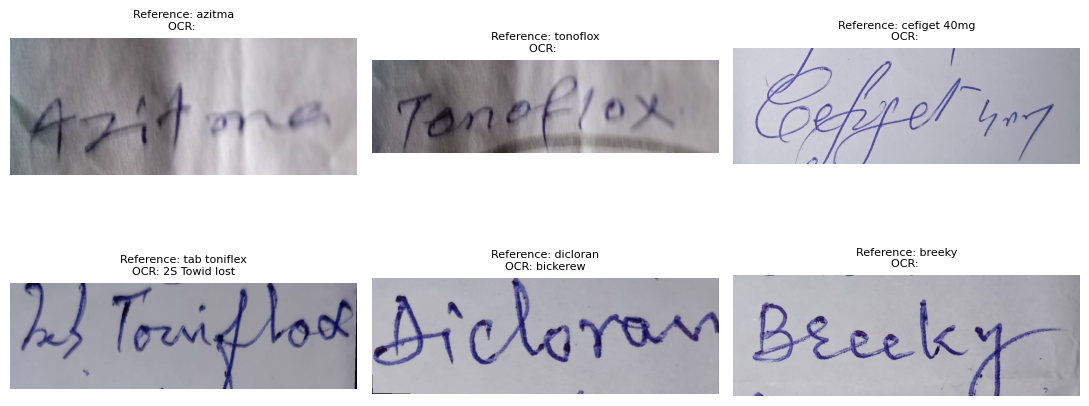

In [8]:
errors = preprocessed[~preprocessed.exact].sort_values(["normalised_edit_distance", "filename"], ascending=[False, True]).head(8)
errors = errors.assign(failure_type=np.select(
    [errors.ocr_status == "engine_error", errors.prediction_norm == ""],["engine error", "no text detected"],
    default="character confusion",))
errors[["filename", "truth", "prediction", "failure_type"]].to_csv(RESULTS / "error_analysis.csv", index=False)
display(errors[["truth", "prediction", "failure_type"]])

fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, row in zip(axes.flat, errors.head(6).itertuples()):
    ax.imshow(load_image(IMAGES / "img" / "img" / row.filename))
    ax.set_title(f"Reference: {row.truth}\nOCR: {row.prediction[:28]}", fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.savefig(RESULTS / "ocr_failures.png", dpi=150)
print("Saved:", sorted(p.name for p in RESULTS.iterdir() if p.is_file()))